# How Neural Networks Learn - Solution

**Business problem:** improve a spam filter without increasing costly mistakes on new emails. One observation is one email: **0 = ham, 1 = spam**. A flagged email enters a review queue; it should not be deleted automatically.

In this notebook, we will:
1. Calculate a forward pass, backward pass and simultaneous parameter update using supplied gradient rules.
2. Compare learning rates under the same training budget.
3. Interpret training/validation curves, capacity, regularization and checkpoint selection.
4. Recommend a model using validation evidence and explicit error costs.

Read the [concept notebook](how_neural_networks_learn_concept.ipynb) first. This is the completed companion to the [exercise](how_neural_networks_learn_exercise.ipynb). Run from top to bottom; the five numbered activities, variables and settings match the exercise. Complete code, plots, expected answers, marking criteria and common mistakes are provided. Interpret the evidence before expanding the self-check answers.

This accompanies **SW07 Lecture 2: How Neural Networks Learn**. It assumes sigmoid/ReLU predictions, training/validation/test splits, precision and recall. Gradient rules are supplied; no calculus derivation is required.

Activities 1-3 are alternative 10-minute worked activities for a lecture; choose only one for the demonstration slot of a 45-minute lecture. Activities 4 and 5 are optional 15-minute practicals. The complete sequence takes about **60 minutes plus execution time** and belongs in a separate practical session. The small examples are constructed, while the later learning curves are measured model results.

The real-data experiments read the repository's prepared email CSV and shared feature helper. No raw email text or download is required. Keep the test set untouched.

## Libraries and settings

The small demonstrations are constructed illustrations, not measured spam-filter performance. They need only NumPy, pandas and matplotlib. The practical additionally uses scikit-learn and the repository's local feature-only email CSV; no raw emails or download are required.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 7
np.random.seed(SEED)

## 1. When should training stop?

**Short activity: 10 minutes.** Predict which checkpoint you would retain before inspecting the table.

The following curves are **constructed teaching illustrations, not an observed training run**. The dotted portion shows hypothetical continued training after stopping. No email predictions or business costs have been measured for these curves.

**Coding task:** set `best_epoch` to the integer epoch corresponding to the lowest `validation_bce`. `np.argmin` returns an array position, whereas `epochs` holds epoch labels. The curves, patience calculation, plot and table are supplied.

The initial validation loss supplies a no-improvement reference for this illustration. The real-data experiments later establish a statistical baseline using the training spam proportion.

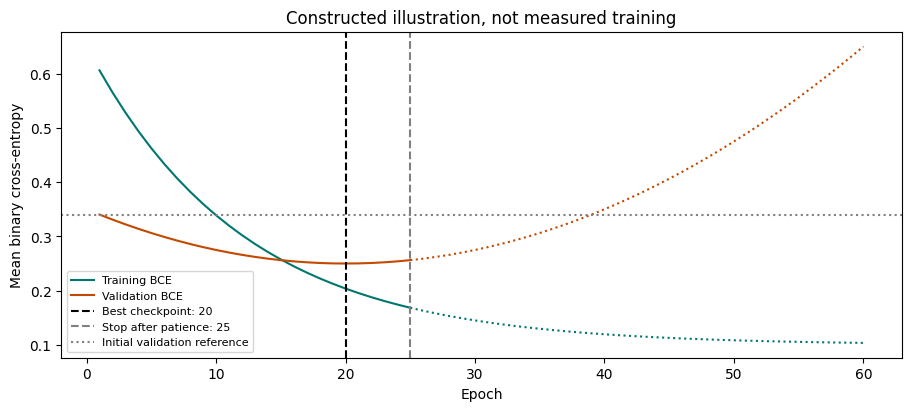

,epoch,training_bce,validation_bce
19,20,0.2039,0.2500
24,25,0.1685,0.2562
59,60,0.1037,0.6500


In [2]:
epochs = np.arange(1, 61)
training_bce = 0.55 * np.exp(-epochs / 12) + 0.1
validation_bce = 0.25 + 0.00025 * (epochs - 20) ** 2
best_epoch = int(epochs[np.argmin(validation_bce)])
patience = 5
stopping_epoch = best_epoch + patience

figure, axis = plt.subplots(figsize=(9, 4), constrained_layout=True)
for values, name, color in [(training_bce, 'Training BCE', '#00776E'),
                            (validation_bce, 'Validation BCE', '#C34800')]:
    observed = epochs <= stopping_epoch
    continued = epochs >= stopping_epoch
    axis.plot(epochs[observed], values[observed], label=name, color=color)
    axis.plot(epochs[continued], values[continued], linestyle=':', color=color)
axis.axvline(best_epoch, color='black', linestyle='--', label=f'Best checkpoint: {best_epoch}')
axis.axvline(stopping_epoch, color='gray', linestyle='--', label=f'Stop after patience: {stopping_epoch}')
axis.axhline(validation_bce[0], color='gray', linestyle=':', label='Initial validation reference')
axis.set(xlabel='Epoch', ylabel='Mean binary cross-entropy',
         title='Constructed illustration, not measured training')
axis.legend(fontsize=8)
plt.show()
illustration = pd.DataFrame({'epoch': epochs, 'training_bce': training_bce,
                             'validation_bce': validation_bce})
display(illustration.loc[illustration.epoch.isin([best_epoch, stopping_epoch, 60])].round(4))

### Explain your decision
1. Which checkpoint would you retain, and which curve supports that choice?
2. With patience of five complete epochs without improvement, why stop later than the best checkpoint?
3. Does lower validation BCE necessarily mean lower business cost or better performance on future email?

**Deliverable:** annotate the two selected epochs and write a three-sentence recommendation.

<details>
<summary>Expected answers and self-check criteria</summary>

1. **Basic, 2 points:** retain epoch 20 (1), because it has the lowest validation BCE (1). Common mistake: retain epoch 60 because training loss is smallest.
2. **Intermediate, 2 points:** stop after epoch 25 (1), then restore epoch 20 rather than the last weights (1). Patience waits for possible improvement; it does not make the last checkpoint best. The dotted continuation is hypothetical.
3. **Intermediate, 2 points:** BCE evaluates probabilities, not thresholded error costs (1); future performance still needs independent evidence (1). Common mistake: infer false-positive counts or cost savings from a loss curve alone.

</details>

## 2. Backpropagation by hand

**Alternative lecture activity: 10 minutes.** How can feedback from one labelled email change both layers of a tiny network? Work on paper before opening the answers. No dataset or training run is needed.

### A deliberately small spam filter

A synthetic email contains two promotional keyword matches: input $x=2$. Its known label is spam, $y=1$. The network has one hidden ReLU neuron and one sigmoid output:

$$h=\operatorname{ReLU}(w_1x+b_1),\qquad z=w_2h+b_2,\qquad p=\frac{1}{1+e^{-z}}.$$

Here $h$ is the hidden activation, $z$ the output score, and $p$ the predicted spam probability. ReLU returns the larger of zero and its input. The two weights are $w_1,w_2$; the two biases are $b_1,b_2$.

| Parameter | Initial value |
|---|---:|
| $w_1$ | 0.50 |
| $b_1$ | 0.00 |
| $w_2$ | 0.40 |
| $b_2$ | -0.40 |
| Learning rate $\eta$ | 0.10 |

### 1. Predict forward: 2 minutes

Calculate the hidden activation $h$, output score $z$, spam probability $p$, and loss $L$. For this spam email, binary cross-entropy is $L=-\ln(p)$, where $\ln$ means natural logarithm. A calculator is sufficient.

### 2. Send feedback backward: 4 minutes

Use these supplied rules; do not derive them:

- For a sigmoid output with binary cross-entropy, output feedback is $g=p-y$.
- Feedback through a connection is multiplied by that connection's weight.
- A weight's gradient is the receiving neuron's feedback multiplied by the connection's input; a bias's gradient is just that neuron's feedback.
- ReLU passes feedback unchanged when its input is positive. Its input is positive here.

A gradient tells us how loss responds to a small parameter change. Complete this worksheet using the **original** parameters:

| Quantity | Calculation | Your answer |
|---|---|---|
| Output feedback | $g=p-y$ | |
| Gradient for $w_2$ | $g\,h$ | |
| Gradient for $b_2$ | $g$ | |
| Hidden feedback | $g\,w_2$ | |
| Gradient for $w_1$ | $(g\,w_2)x$ | |
| Gradient for $b_1$ | $g\,w_2$ | |

### 3. Update together: 2 minutes

For each parameter, use **new parameter = old parameter - learning rate x gradient**. Calculate all four gradients first, then update all parameters together. This is one plain gradient-descent step, without Adam, momentum, regularization or a batch of other emails.

### 4. Predict again and interpret: 2 minutes

Use the updated parameters to calculate the new probability and loss. Did the loss decrease? Does that establish improved performance on unseen emails? Which stage calculated the gradients, and which stage changed the parameters?

**Deliverable:** completed worksheet, four updated parameters, and a two-sentence interpretation. The input count and label are constructed; this exercise is not evidence that keyword counts alone form a useful spam filter.

<details>
<summary>Worked answers, marking criteria and common mistakes</summary>

**1. Forward pass: basic, 1 point.** $h=1$, $z=0$, $p=0.5$, and $L\approx0.693$. Award the point for the correct probability and loss. Common mistake: treating the output score $z$ as a probability.

**2. Backward pass: intermediate, 2 points.** Output feedback is $g=-0.5$. Gradients for $w_2$ and $b_2$ are both $-0.5$. Hidden feedback is $-0.2$, giving gradients $-0.4$ for $w_1$ and $-0.2$ for $b_1$. Award one point for output gradients and one for hidden gradients. Common mistakes: forgetting the connecting weight $w_2$ or the input multiplier $x$.

**3. Update: basic, 1 point.** $w_1=0.54$, $b_1=0.02$, $w_2=0.45$, $b_2=-0.35$. Award the point for all four updates. Subtracting a negative gradient increases a parameter. Common mistakes: adding gradients or using an already updated $w_2$ to calculate hidden feedback.

**4. Recheck and interpretation: intermediate, 2 points.** The new hidden activation is $1.10$, score $0.145$, probability approximately $0.536$, and loss approximately $0.623$. Award one point for explaining that loss fell on this training email but generalization is untested, and one for distinguishing backpropagation (calculates gradients) from the optimizer update (changes parameters). Common mistake: claiming that a better fit to one training email establishes a better spam filter. A single gradient-descent step is not guaranteed to reduce loss for every learning rate or dataset.

</details>

### Numerical check and coding tasks

Complete the worksheet before running the following cell. It verifies the hand calculation, not generalization. The loss formula and gradient rules apply to the known spam label $y=1$ and the positive ReLU input in this constructed example.

**Coding tasks:** calculate `hand_output_feedback` from the predicted spam probability and the known target 1. Then calculate `hand_hidden_feedback` by multiplying that output feedback by the **original output weight**, the third entry of `hand_initial_parameters` (index 2).

The remaining gradient calculations, forward-pass function, tables and simultaneous update are supplied. All gradients use the original parameters; no parameter is changed before its feedback is calculated. This is plain gradient descent, not Adam.

In [3]:
from math import exp, log


def hand_forward(parameters):
    input_weight, hidden_bias, output_weight, output_bias = parameters
    hidden = max(0.0, input_weight * 2.0 + hidden_bias)
    score = output_weight * hidden + output_bias
    probability = 1.0 / (1.0 + exp(-score))
    return {'hidden_activation': hidden, 'score': score,
            'spam_probability': probability, 'bce': -log(probability)}


hand_initial_parameters = (0.5, 0.0, 0.4, -0.4)
hand_before = hand_forward(hand_initial_parameters)
hand_output_feedback = hand_before['spam_probability'] - 1.0
hand_hidden_feedback = hand_output_feedback * hand_initial_parameters[2]
hand_gradients = (hand_hidden_feedback * 2.0, hand_hidden_feedback,
                  hand_output_feedback * hand_before['hidden_activation'], hand_output_feedback)
hand_updated_parameters = tuple(parameter - 0.1 * gradient
                                for parameter, gradient in zip(hand_initial_parameters, hand_gradients))
hand_after = hand_forward(hand_updated_parameters)
display(pd.DataFrame({'initial': hand_initial_parameters, 'gradient': hand_gradients,
                      'updated': hand_updated_parameters}, index=['w1', 'b1', 'w2', 'b2']))
display(pd.DataFrame([hand_before, hand_after], index=['Before update', 'After update']).round(6))

,initial,gradient,updated
w1,0.5,-0.4,0.54
b1,0.0,-0.2,0.02
w2,0.4,-0.5,0.45
b2,-0.4,-0.5,-0.35


,hidden_activation,score,spam_probability,bce
Before update,1.0,0.000,0.500000,0.693147
After update,1.1,0.145,0.536187,0.623273


## Optional experiments: learn from real emails

From here onward, curves and metrics are **measured model results**, not the constructed illustration. We read [the prepared local CSV](../../../00_Data/email_spam.csv), which contains 16 numerical email features and the companion notebook's stored 60/20/20 training, validation and test partitions. Metadata such as labels, split names, source rows and message hashes must not become predictors.

To keep experiments small, use a stratified subset of **1,000 training emails** and **1,200 validation emails**. Every configuration receives these same rows. Smaller training data can make capacity effects easier to inspect, but does not guarantee visible overfitting. Scaling is fitted only on the training subset. The test partition is loaded but never transformed or evaluated.

### Libraries and settings

Use the repository environment described by [requirements.txt](../../../requirements.txt). This notebook needs NumPy, pandas, matplotlib and scikit-learn; installed versions are displayed below. The local feature helper is shared with [the classification notebook](../lecture1/logistic_regression_to_neural_network_concept.ipynb). No raw emails or dataset download are required.

In [4]:
from pathlib import Path
from copy import deepcopy
import importlib.metadata
import sys
from sklearn.dummy import DummyClassifier
from sklearn.metrics import log_loss, precision_score, recall_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

roots = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next((root for root in roots
                  if (root / '00_Data' / 'email_spam.csv').is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError('Open this notebook from inside python_machine_learning_basics; 00_Data/email_spam.csv must be present.')
DATA_DIR = REPO_ROOT / '00_Data'
NOTEBOOK_DIR = REPO_ROOT / '08_Neural_Networks' / 'HS2026'
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))
from enron_features import EmailFeatures, FEATURE_NAMES

print('Data directory:', DATA_DIR)
display(pd.Series({name: importlib.metadata.version(name)
                   for name in ['numpy', 'pandas', 'matplotlib', 'scikit-learn']},
                  name='Installed version'))

Data directory: /Users/iaracena/VisualStudioProjects/ZHAW/python_machine_learning_basics/00_Data


numpy           1.26.4
pandas           2.2.3
matplotlib       3.9.4
scikit-learn     1.6.1
Name: Installed version, dtype: object

In [5]:
email_data_path = DATA_DIR / 'email_spam.csv'
prepared_emails = pd.read_csv(email_data_path)
train = prepared_emails.loc[prepared_emails['split'].eq('train')].copy()
validation = prepared_emails.loc[prepared_emails['split'].eq('validation')].copy()
test = prepared_emails.loc[prepared_emails['split'].eq('test')].copy()

train_small, _ = train_test_split(train, train_size=1000,
                                 stratify=train['label'], random_state=SEED)
validation_small, _ = train_test_split(validation, train_size=1200,
                                      stratify=validation['label'], random_state=SEED)
features = EmailFeatures()
train_features = features.fit_transform(train_small[list(FEATURE_NAMES)])
validation_features = features.transform(validation_small[list(FEATURE_NAMES)])
scaler = StandardScaler()
X_train_small = scaler.fit_transform(train_features)
X_validation_small = scaler.transform(validation_features)
y_train_small = train_small['label'].to_numpy()
y_validation_small = validation_small['label'].to_numpy()
print('Loaded:', email_data_path.resolve())
print(f'Prepared {len(train_small):,} training and {len(validation_small):,} validation emails. Test data remains unused.')

Loaded: /Users/iaracena/VisualStudioProjects/ZHAW/python_machine_learning_basics/00_Data/email_spam.csv
Prepared 1,000 training and 1,200 validation emails. Test data remains unused.


## Establish a baseline and a decision rule

A prior baseline assigns every email the training-set spam proportion. A network should be compared with this no-feature baseline, not only with other networks.

**BCE** evaluates predicted probabilities; lower is better. We calculate the same unpenalized mean BCE on training and validation data. We do not compare a penalized training objective with an unpenalized validation loss.

For decisions, keep the threshold fixed at **0.5** across configurations. Report precision, recall and **assumed cost = 5 x false positives + false negatives**, expressed per 1,000 emails. These are example cost units, not financial estimates. A fixed threshold makes this comparison easier to interpret; it is not an optimized review policy.

In [6]:
def validation_metrics(model):
    probabilities = model.predict_proba(X_validation_small)[:, 1]
    predictions = probabilities >= 0.5
    true_negative, false_positive, false_negative, true_positive = confusion_matrix(
        y_validation_small, predictions, labels=[0, 1]).ravel()
    return {
        'validation_bce': log_loss(y_validation_small, probabilities, labels=[0, 1]),
        'precision': precision_score(y_validation_small, predictions, zero_division=0),
        'recall': recall_score(y_validation_small, predictions, zero_division=0),
        'false_positives': int(false_positive),
        'false_negatives': int(false_negative),
        'cost_per_1000': 1000 * (5 * false_positive + false_negative) / len(y_validation_small),
    }

prior = DummyClassifier(strategy='prior', random_state=SEED).fit(X_train_small, y_train_small)
baseline_metrics = validation_metrics(prior)
baseline_bce = baseline_metrics['validation_bce']
display(pd.DataFrame([baseline_metrics], index=['Training-prior baseline']).round(4))

,validation_bce,precision,recall,false_positives,false_negatives,cost_per_1000
Training-prior baseline,0.608,0.0,0.0,0,356,296.6667


## Training support

The helper below runs one epoch per `partial_fit` call, retaining weights and Adam's optimizer state. It records prediction BCE on both partitions and saves a copy whenever validation BCE improves.

These experiments run for a fixed **80 epochs**; they do **not** stop early. The retained best checkpoint and the final model are different objects. Early stopping with patience was illustrated in Exercise 1. The best observed checkpoint uses the full validation trajectory; an online stopping rule would not know future losses.

Focus on the resulting curves and tables rather than the helper implementation. No derivatives are required.

In [7]:
def fit_with_history(hidden_layers, l2_strength, epochs=80, learning_rate=0.001):
    model = MLPClassifier(
        hidden_layer_sizes=hidden_layers, activation='relu', solver='adam',
        alpha=l2_strength, batch_size=64, learning_rate_init=learning_rate,
        early_stopping=False, random_state=SEED,
    )
    records = []
    best_loss = float('inf')
    best_model = None
    for epoch in range(1, epochs + 1):
        model.partial_fit(X_train_small, y_train_small, classes=np.array([0, 1]))
        train_loss = log_loss(y_train_small, model.predict_proba(X_train_small)[:, 1], labels=[0, 1])
        validation_loss = log_loss(y_validation_small, model.predict_proba(X_validation_small)[:, 1], labels=[0, 1])
        records.append({'epoch': epoch, 'training_bce': train_loss, 'validation_bce': validation_loss})
        if validation_loss < best_loss:
            best_loss = validation_loss
            best_model = deepcopy(model)
    return model, best_model, pd.DataFrame(records)


def plot_histories(histories, title):
    figure, axes = plt.subplots(1, len(histories), figsize=(5 * len(histories), 3.5),
                                squeeze=False, constrained_layout=True)
    for axis, (name, history) in zip(axes.ravel(), histories.items()):
        axis.plot(history['epoch'], history['training_bce'], label='Training')
        axis.plot(history['epoch'], history['validation_bce'], '--', label='Validation')
        axis.axhline(baseline_bce, color='gray', linestyle=':', label='Prior validation baseline')
        best_epoch = int(history.loc[history['validation_bce'].idxmin(), 'epoch'])
        axis.axvline(best_epoch, color='gray', alpha=0.4)
        axis.set(title=name, xlabel='Epoch', ylabel='Mean prediction BCE')
        axis.legend(fontsize=8)
    figure.suptitle(title)
    plt.show()


def result_row(name, result):
    final_model, best_model, history = result
    best_row = history.loc[history['validation_bce'].idxmin()]
    return {
        'configuration': name,
        'parameters': sum(weights.size for weights in best_model.coefs_)
                      + sum(bias.size for bias in best_model.intercepts_),
        'best_epoch': int(best_row['epoch']),
        'training_bce_at_best': best_row['training_bce'],
        **validation_metrics(best_model),
        'final_validation_bce': history.iloc[-1]['validation_bce'],
    }

## 3. Does faster learning produce a better spam filter?

**Alternative lecture activity: 10 minutes with prepared code and outputs.** Choose one of activities 1, 2 or 3 for the lecture's demonstration slot; the full sequence belongs in a separate practical.

Keep the rows, `(32,)` architecture, seed, Adam optimizer, batch size 64, `l2_strength=0.01`, threshold 0.5 and 80-epoch budget fixed. Change only Adam's initial learning rate:

| Setting | Learning rate |
|---|---:|
| Smaller steps | `0.0001` |
| Baseline | `0.001` |
| Larger steps | `0.01` |

**Coding task:** complete `assumed_total_cost` as five times the false-positive count plus the false-negative count from `metrics`. This is total assumed cost; `cost_per_1000` additionally normalizes by validation sample size.

1. Predict which rate should reduce training loss fastest. Could it also perform worse?
2. Inspect both curves and final-epoch validation precision, recall, false positives and false negatives. Compare costs with the prior baseline; a policy that flags nothing may be cheap but useless for finding spam.
3. Submit the table and a three-sentence recommendation explaining evidence and limitations.

**Checkpoint convention:** this table compares the **final models after the same 80 epochs**, not their best checkpoints. Plot markers show the best observed validation BCE for context only. Activities 4 and 5 instead report best-validation-BCE checkpoints. Do not prescribe a winning learning rate or use test results to tune these experiments.

,epoch,training_bce,validation_bce,precision,recall,false_positives,false_negatives,cost_per_1000,assumed_total_cost
configuration,,,,,,,,,
rate=0.0001,80,0.5502,0.5632,0.7031,0.1264,19,311,338.3333,406
rate=0.001,80,0.3371,0.4295,0.7351,0.6236,80,134,445.0000,534
rate=0.01,80,0.2025,0.4566,0.7676,0.7051,76,105,404.1667,485


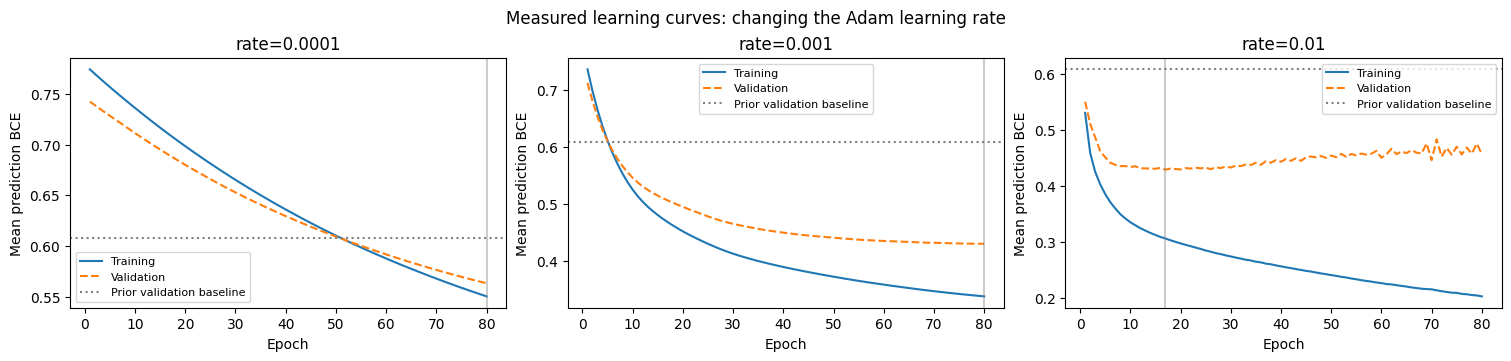

In [8]:
learning_rate_results = {
    f'rate={rate}': fit_with_history((32,), l2_strength=0.01, learning_rate=rate)
    for rate in [0.0001, 0.001, 0.01]
}
learning_rate_rows = []
for name, (final_model, best_model, history) in learning_rate_results.items():
    metrics = validation_metrics(final_model)
    learning_rate_rows.append({
        'configuration': name,
        'epoch': int(history.iloc[-1]['epoch']),
        'training_bce': history.iloc[-1]['training_bce'],
        **metrics,
        'assumed_total_cost': 5 * metrics['false_positives'] + metrics['false_negatives'],
    })
learning_rate_table = pd.DataFrame(learning_rate_rows).set_index('configuration')
display(learning_rate_table.round(4))
plot_histories({name: result[2] for name, result in learning_rate_results.items()},
               'Measured learning curves: changing the Adam learning rate')

<details>
<summary>Exercise 3: expected answers and self-check criteria</summary>

1. **Basic, 2 points:** the largest rate need not learn fastest or best (1); large steps may overshoot or make Adam's optimization unstable (1). Interpret the observed curves rather than assuming a winner. Common mistake: larger rate always means better learning.
2. **Intermediate, 2 points:** lowest training BCE is not sufficient for selection (1); use validation BCE, precision, recall and observed errors to assess generalization and the decision policy (1). Common mistake: compare a best checkpoint for one rate with the final epoch for another.
3. **Intermediate, 2 points:** support a recommendation with measured validation errors and the stated 5:1 cost assumption (1); acknowledge one seed, a short fixed budget and the need for independent evaluation (1). Common mistake: claim a universally optimal rate or ignore that a no-flag policy may have low cost and zero recall.

A slower rate may simply need more epochs. This activity compares rates within the same budget, not their best achievable performance after unlimited training. Threshold optimization is a separate decision.

</details>

## 4. Can a larger network perform worse?

**Optional practical: 15 minutes.** Compare `(8,)`, `(32,)` and `(128, 128)` hidden-layer configurations. Keep the same rows, seed, Adam settings, regularization coefficient and 80-epoch budget.

1. Which configuration fits the training data best? Use the curves, not only parameter counts.
2. Which has the lowest validation BCE? Does the gap widen as training continues?
3. Recommend a checkpoint and configuration. Does its validation cost at threshold 0.5 support the same choice?

**Deliverable:** a comparison table and a three-sentence conclusion. Do not assume that the largest network must overfit. The table's metrics describe each model's best-validation-BCE checkpoint. Repeated validation comparisons can themselves overfit the validation set.

,parameters,best_epoch,training_bce_at_best,validation_bce,precision,recall,false_positives,false_negatives,cost_per_1000,final_validation_bce
configuration,,,,,,,,,,
"Small (8,)",145,80,0.4079,0.4592,0.6816,0.5112,85,174,499.1667,0.4592
"Medium (32,)",577,80,0.3371,0.4295,0.7351,0.6236,80,134,445.0000,0.4295
"Large (128,128)",18817,21,0.2825,0.4160,0.7638,0.6629,73,120,404.1667,0.4887


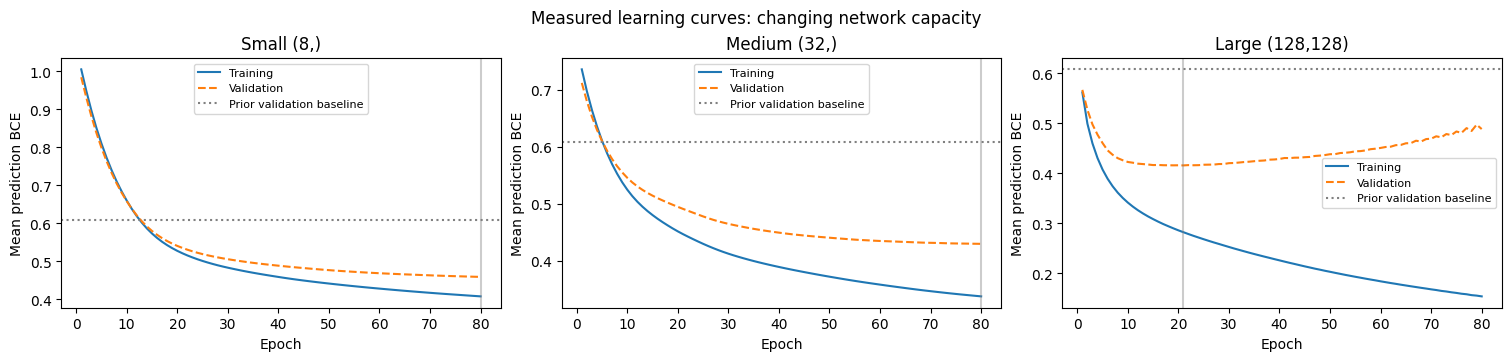

In [9]:
capacity_configs = {'Small (8,)': (8,), 'Medium (32,)': (32,), 'Large (128,128)': (128, 128)}
capacity_results = {name: fit_with_history(layers, l2_strength=0.01)
                    for name, layers in capacity_configs.items()}
capacity_table = pd.DataFrame([result_row(name, result)
                               for name, result in capacity_results.items()]).set_index('configuration')
display(capacity_table.round(4))
plot_histories({name: result[2] for name, result in capacity_results.items()},
               'Measured learning curves: changing network capacity')

<details>
<summary>Exercise 4: expected reasoning and self-check criteria</summary>

1. **Basic, 1 point:** identify training fit from the measured curves. A larger network may fit better, but that result is not guaranteed. Common mistake: infer fitting quality from network size alone.
2. **Intermediate, 2 points:** identify the best observed validation BCE (1) and explain whether falling training loss accompanies stagnating or worsening validation loss (1). This supports an overfitting interpretation, not proof of a unique cause. Common mistake: the smallest gap must be best; an underfit model can have a small gap.
3. **Intermediate, 2 points:** support a recommendation with observed validation evidence (1) and distinguish probability loss from threshold-specific business cost (1). A cost-based decision may differ from a BCE-based choice. Common mistake: declare a universal winner from one seed and subset.

There is no predetermined winning configuration. An absence of visible overfitting is a result to interpret, not a failed exercise.

</details>

## 5. Can L2 regularization help?

**Optional practical: 15 minutes.** Fix the large `(128, 128)` architecture. Compare `l2_strength = 0.01`, `1.0` and `10.0`. Reuse the previous `0.01` run. Keep the data, seed, batch size, learning rate and epoch budget fixed.

**What L2 adds:** training balances prediction error against a penalty on large connection weights:

$$\text{training objective} = \text{prediction BCE} + \text{L2 penalty}.$$

The penalty grows with the sum of squared weights, $\sum_j w_j^2$, where $w_j$ is one learned connection weight. A weight of 2 contributes 4 to this sum; a weight of 1 contributes 1. This encourages smaller weights rather than simply adding more layers or removing neurons.

**What the strength controls:** `l2_strength = 0` removes the L2 penalty; larger values give it more influence during training. Our helper passes this value to scikit-learn as `alpha=l2_strength`. Scikit-learn also normalizes the penalty by sample size, so the same numeric strength is not automatically equivalent across libraries. The deliberately separated settings here illustrate a range, not universal recommended values.

**Why it can help:** discouraging large weights can reduce fitting to training-specific patterns. Training prediction BCE may increase while validation BCE improves. Too strong a penalty can instead cause underfitting, with poor predictions on both partitions. Unlike dropout, L2 does not randomly mask activations.

1. Can stronger L2 regularization increase training prediction BCE while improving validation BCE?
2. Which curves suggest underfitting rather than overfitting?
3. Which configuration would you recommend under the stated error costs, and what evidence is still missing?

**Deliverable:** a three-sentence recommendation supported by the table. The displayed losses are unpenalized prediction BCE on both partitions for a comparable scale; the penalty affects training updates but is not added to these reported metrics.

,parameters,best_epoch,training_bce_at_best,validation_bce,precision,recall,false_positives,false_negatives,cost_per_1000,final_validation_bce
configuration,,,,,,,,,,
L2 strength=0.01,18817,21,0.2825,0.4160,0.7638,0.6629,73,120,404.1667,0.4887
L2 strength=1.0,18817,80,0.3450,0.4301,0.7617,0.5927,66,145,395.8333,0.4301
L2 strength=10.0,18817,6,0.6040,0.6055,0.0000,0.0000,0,356,296.6667,0.6081


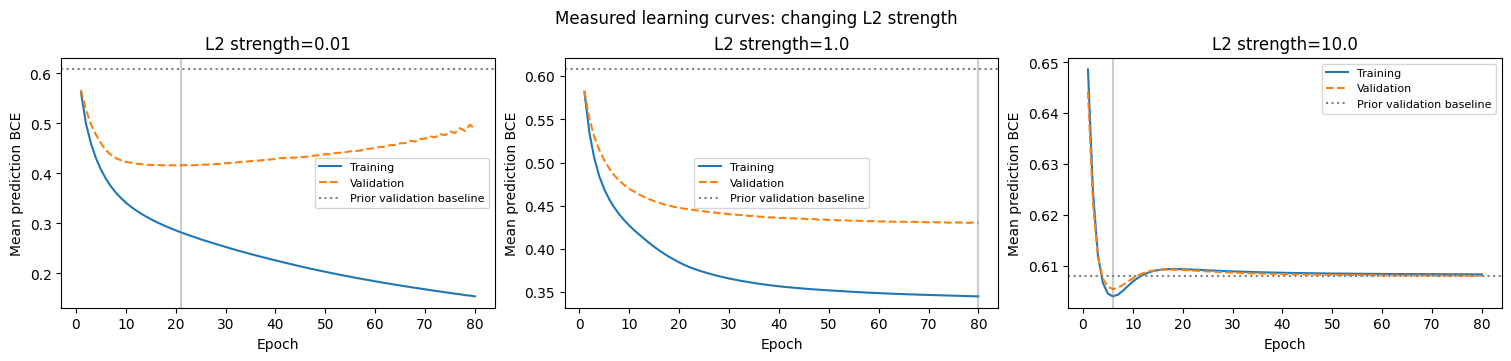

In [10]:
regularization_results = {'L2 strength=0.01': capacity_results['Large (128,128)']}
for l2_strength in [1.0, 10.0]:
    regularization_results[f'L2 strength={l2_strength}'] = fit_with_history((128, 128), l2_strength=l2_strength)
regularization_table = pd.DataFrame([result_row(name, result)
                                     for name, result in regularization_results.items()]).set_index('configuration')
display(regularization_table.round(4))
plot_histories({name: result[2] for name, result in regularization_results.items()},
               'Measured learning curves: changing L2 strength')

<details>
<summary>Exercise 5: expected reasoning and self-check criteria</summary>

1. **Intermediate, 2 points:** yes, a penalty can discourage fitting training-specific patterns (1), so higher training prediction loss can coexist with better validation loss (1). Common mistake: reject regularization whenever training loss rises.
2. **Intermediate, 2 points:** persistently poor training and validation performance can suggest underfitting (1); compare against the prior baseline and other configurations (1). Common mistake: interpret a small gap alone as success. Optimization difficulties may also explain weak results.
3. **Intermediate, 3 points:** cite the observed validation errors/cost (1), state that costs and threshold are assumptions (1), and require independent evaluation or repeated-seed evidence before deployment (1). Common mistake: claim the strongest penalty is always best.

Use the measured results; no L2 strength is guaranteed to win.

</details>

## Interpretation and business implications

Return to the decision: which emails should enter a review queue?

- More parameters or epochs can improve fitting without improving validation performance.
- Early stopping selects a checkpoint; regularization changes the training objective. They are related controls, not identical mechanisms.
- Lowest validation BCE and lowest cost at a fixed threshold can select different models. State the criterion before making a recommendation.
- The assumed 5:1 costs are not monetary savings, and neither table measures review capacity or production performance.

**Read the baseline carefully.** In the saved example run, the prior policy flags no emails: it has zero recall but a lower assumed cost than the networks at threshold 0.5. The strongly regularized network can match that policy while learning little useful discrimination. Lower cost alone therefore does not establish that a useful spam-screening service has been built. State any minimum recall requirement explicitly rather than changing costs after seeing the results.

**Read the checkpoint comparison carefully.** Compare each best checkpoint with its final checkpoint, not only with another architecture. Stronger regularization may improve the final model without beating the lightly regularized model's best earlier checkpoint. Use your displayed results rather than assume a universal winner.

A later experiment could choose thresholds on validation data, then assess fixed choices independently. Do not turn previously inspected test results into another tuning signal.

## Limitations

- These experiments use only 1,000 training emails, one seed and 80 epochs. Models may not converge; conclusions can change with sample size and optimization settings.
- Architecture changes also change parameter count; the comparison does not isolate depth alone. Repeated validation selection can produce optimistic estimates.
- Exact duplicates are removed, but related messages or campaigns can span partitions. Random historical splits do not establish performance on future email.
- No test evaluation is performed here. The companion notebook's historical test set has already been inspected, so it would not supply fresh confirmation for further development.
- Simple counts miss meaning; dataset rights and upstream labels are not independently audited. Protect emails and models. These associations are not causal explanations.

## Further exercise

Repeat a small, predeclared comparison across three random seeds or two training sample sizes while retaining the same outer validation partition. Report variation, not just the best result. Plan a fresh final assessment before using existing evaluation results to guide further development.

**Advanced, 3 points:** document comparable settings (1), report variability (1), distinguish development evidence from independent confirmation (1). Common mistake: present the best seed as expected performance.

## References

**Required student reading:** James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). *An Introduction to Statistical Learning: With Applications in Python*. Springer. Instructor-selected neural-network training material. https://www.statlearning.com/

**Optional reading / instructor reference:** Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep Learning*. MIT Press. Chapter 7, Regularization for Deep Learning. https://www.deeplearningbook.org/contents/regularization.html

**Dataset:** NIKHIL CHAUDHARY 7108. (n.d.). *Spam email dataset(ENRON, TREC and others)*. Kaggle. https://www.kaggle.com/datasets/nikhilchaudhary7108/spam-email-datasetenron-trec-and-others . Combined-source provenance and upstream rights have not been independently audited. This notebook reads the repository's prepared feature-only [email_spam.csv](../../../00_Data/email_spam.csv), not the upstream raw messages.

**Official technical documentation:** [MLPClassifier and partial_fit](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html), [log_loss](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.log_loss.html).

**Environment:** [Repository requirements](../../../requirements.txt). Installed package versions are displayed in the experiment setup; the session footer records the runtime.

### Jupyter notebook - footer info

Include this information when submitting your notebook.

In [11]:
import platform
from datetime import datetime

print(platform.platform())
print('Python:', platform.python_version())
print('Date:', datetime.now().isoformat(timespec='seconds'))

macOS-26.6.2-arm64-i386-64bit
Python: 3.11.11
Date: 2026-10-26T00:25:22
